# COMP4318/5318 Assignment 2: Image Classification

### Group number: 184 , SID1: 540988262 , SID2: 540859412 , SID3: 550271057

## Setup and dependencies
Please use this section to list and set up all your required libraries/dependencies and your plotting environment.

We use numpy, pandas, matplotlib and seaborn for data handling and plots, scikit-learn for the Random Forest, and TensorFlow/Keras with KerasTuner for the neural networks. If something is missing it can be installed with
`pip install numpy pandas matplotlib seaborn scikit-learn tensorflow keras-tuner`.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # hide TensorFlow info messages

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

import tensorflow as tf
from tensorflow import keras
import keras_tuner

# Fix the random seeds so that the results are repeatable
SEED = 42
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

# Plot settings
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

print("TensorFlow version:", tf.__version__)
print("KerasTuner version:", keras_tuner.__version__)

I0000 00:00:1792736283.855164    9386 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792736285.133089    9386 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow version: 2.21.0
KerasTuner version: 1.4.8


## 1. Data loading, exploration, and preprocessing

Code to load the dataset is provided in the following cell. Please proceed with your data exploration and preprocessing in the remainder of this section.

In [2]:
# Load the dataset training and test sets as numpy arrays
# assuming Assignment2Data folder is present in the same directory
# as the notebook
X_train = np.load('Assignment2Data/X_train.npy')
y_train = np.load('Assignment2Data/y_train.npy')
X_test = np.load('Assignment2Data/X_test.npy')
y_test = np.load('Assignment2Data/y_test.npy')

### 1.1 Shape, data type and labels
The class names are taken from the MedMNIST website (PathMNIST is built from the NCT-CRC-HE-100K colorectal histology dataset).

In [3]:
class_names = ["Adipose", "Background", "Debris", "Lymphocytes", "Mucus",
               "Smooth muscle", "Normal mucosa", "Cancer stroma", "Tumour epithelium"]
n_classes = len(class_names)

print(f"X_train: {X_train.shape}, dtype {X_train.dtype}")
print(f"y_train: {y_train.shape}, dtype {y_train.dtype}")
print(f"X_test:  {X_test.shape}, dtype {X_test.dtype}")
print(f"y_test:  {y_test.shape}, dtype {y_test.dtype}")
print("Pixel values range from", X_train.min(), "to", X_train.max())
print("Labels:", np.unique(y_train))

X_train: (32000, 28, 28, 3), dtype uint8
y_train: (32000,), dtype uint8
X_test:  (8000, 28, 28, 3), dtype uint8
y_test:  (8000,), dtype uint8
Pixel values range from 0 to 255
Labels: [0 1 2 3 4 5 6 7 8]


### 1.2 Number of examples in each class

,class,train count,train %,test count,test %
0,Adipose,3490,10.9,873,10.9
1,Background,3431,10.7,858,10.7
2,Debris,3505,11.0,877,11.0
3,Lymphocytes,3656,11.4,914,11.4
4,Mucus,2950,9.2,737,9.2
5,Smooth muscle,4290,13.4,1072,13.4
6,Normal mucosa,2728,8.5,682,8.5
7,Cancer stroma,3253,10.2,813,10.2
8,Tumour epithelium,4697,14.7,1174,14.7


Largest / smallest class in the training set: 1.72


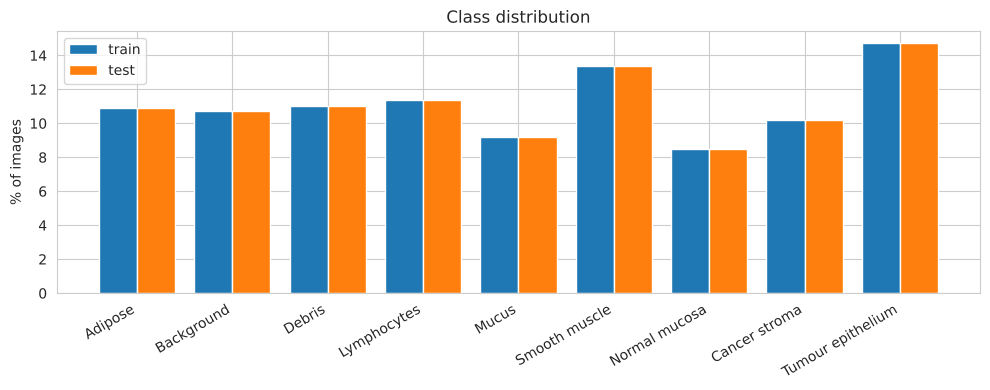

In [4]:
train_counts = np.bincount(y_train)
test_counts = np.bincount(y_test)

class_table = pd.DataFrame({
    "class": class_names,
    "train count": train_counts,
    "train %": np.round(100 * train_counts / len(y_train), 1),
    "test count": test_counts,
    "test %": np.round(100 * test_counts / len(y_test), 1),
})
display(class_table)
print(f"Largest / smallest class in the training set: {train_counts.max() / train_counts.min():.2f}")

x_pos = np.arange(n_classes)
plt.figure(figsize=(10, 4))
plt.bar(x_pos - 0.2, class_table["train %"], width=0.4, label="train")
plt.bar(x_pos + 0.2, class_table["test %"], width=0.4, label="test")
plt.xticks(x_pos, class_names, rotation=30, ha="right")
plt.ylabel("% of images")
plt.title("Class distribution")
plt.legend()
plt.tight_layout()
plt.show()

The classes are not perfectly balanced (tumour epithelium is the biggest class and normal mucosa the smallest, about 1.7 times smaller), but the imbalance is mild and the test set has the same proportions as the training set. We therefore do not resample, but we use stratified splits and also look at the macro F1 score, which gives every class the same weight.

### 1.3 Example images

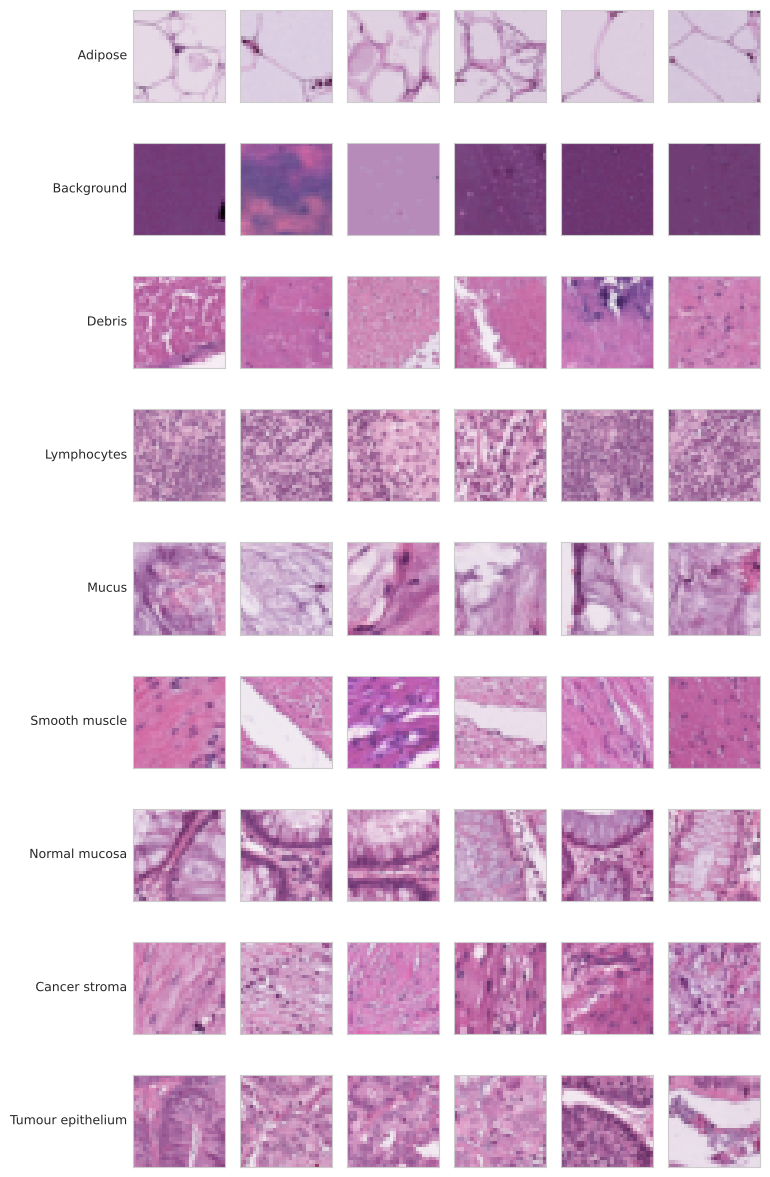

In [5]:
def plot_examples_per_class(images, labels, n_per_class=6):
    """Plot a grid with n_per_class random images for every class (one row per class)."""
    rng = np.random.default_rng(SEED)
    fig, axes = plt.subplots(n_classes, n_per_class, figsize=(n_per_class * 1.3, n_classes * 1.35))
    for c in range(n_classes):
        chosen = rng.choice(np.where(labels == c)[0], n_per_class, replace=False)
        for j, idx in enumerate(chosen):
            axes[c, j].imshow(images[idx])
            axes[c, j].set_xticks([])
            axes[c, j].set_yticks([])
        axes[c, 0].set_ylabel(class_names[c], rotation=0, ha="right", va="center", fontsize=9)
    plt.tight_layout()
    plt.show()

plot_examples_per_class(X_train, y_train)

The images are small pieces of tissue, so there is no single object in the middle of the image. The same kind of tissue can appear anywhere in the patch and in any orientation. A few classes are easy to recognise by eye (adipose is pale with thin cell walls, background is almost uniform), but others look quite similar, for example cancer-associated stroma and smooth muscle (both pink and fibrous), or debris, mucus and tumour epithelium.

### 1.4 Pixel intensities and mean image of each class

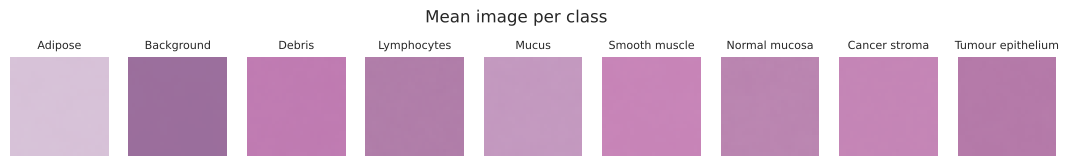

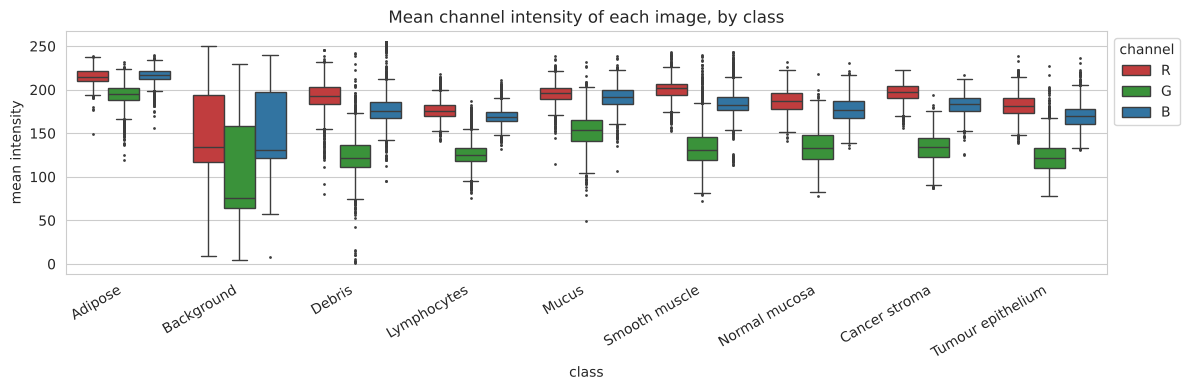

Mean of each channel (R, G, B): [188.7 135.9 180.1]


Std of each channel (R, G, B):  [31.9 45.6 32.2]


In [6]:
# Mean image of each class: if the classes had a typical spatial layout it would show up here
fig, axes = plt.subplots(1, n_classes, figsize=(n_classes * 1.5, 2))
for c in range(n_classes):
    axes[c].imshow(X_train[y_train == c].mean(axis=0).astype(np.uint8))
    axes[c].set_title(class_names[c], fontsize=8)
    axes[c].axis("off")
plt.suptitle("Mean image per class")
plt.show()

# Average R, G and B value of every training image, grouped by class
mean_rgb = X_train.reshape(len(X_train), -1, 3).mean(axis=1)
rgb_df = pd.DataFrame(mean_rgb, columns=["R", "G", "B"])
rgb_df["class"] = [class_names[c] for c in y_train]
rgb_long = rgb_df.melt(id_vars="class", var_name="channel", value_name="mean intensity")

plt.figure(figsize=(12, 4))
ax = sns.boxplot(data=rgb_long, x="class", y="mean intensity", hue="channel", order=class_names,
                 palette={"R": "tab:red", "G": "tab:green", "B": "tab:blue"}, fliersize=1)
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
ax.legend(title="channel", loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.title("Mean channel intensity of each image, by class")
plt.tight_layout()
plt.show()

print("Mean of each channel (R, G, B):", X_train.reshape(-1, 3).mean(axis=0).round(1))
print("Std of each channel (R, G, B): ", X_train.reshape(-1, 3).std(axis=0).round(1))

- The mean images are almost flat, which confirms that the class information is in local texture and colour and not in where things are placed in the image. This should suit a CNN better than the Random Forest or the MLP, which see every pixel position as a separate feature.
- Colour helps for some classes: adipose is the brightest class, and background has a very wide range (from pale pink to dark purple). For the other tissue classes the colour distributions overlap a lot, so texture is needed as well.
- The green channel is darker and more spread out than red and blue. Because the channels have different means and spreads we standardise each channel separately for the neural networks.

### 1.5 PCA view of the raw pixels and duplicate check

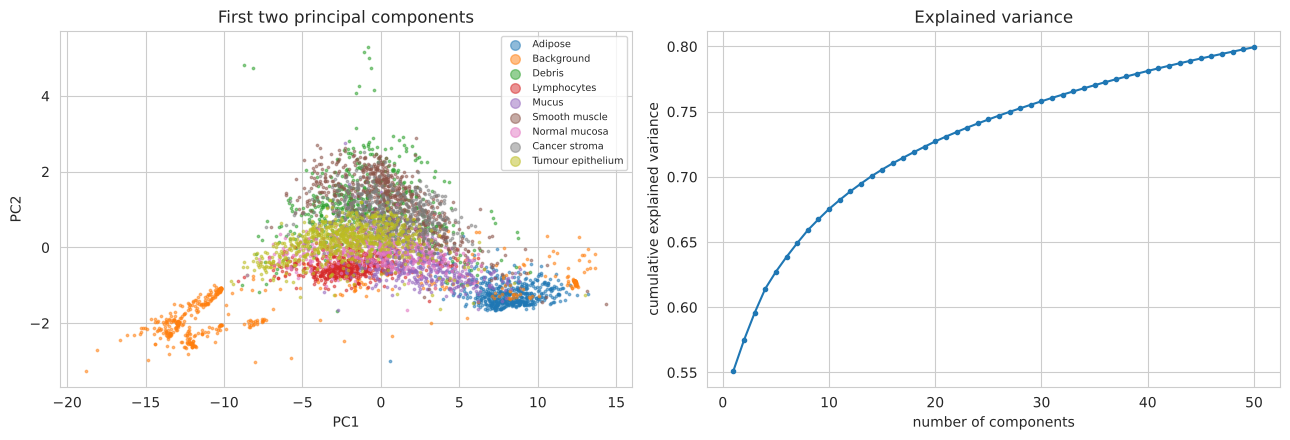

Duplicated images in the training set: 0
Test images that also appear in the training set: 0


In [7]:
# PCA on a stratified subset of 5000 training images
subset_idx, _ = train_test_split(np.arange(len(y_train)), train_size=5000, stratify=y_train, random_state=SEED)
X_subset = X_train[subset_idx].reshape(len(subset_idx), -1) / 255.0
y_subset = y_train[subset_idx]

pca = PCA(n_components=50, random_state=SEED)
X_pca = pca.fit_transform(X_subset)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for c in range(n_classes):
    axes[0].scatter(X_pca[y_subset == c, 0], X_pca[y_subset == c, 1], s=3, alpha=0.5, label=class_names[c])
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].set_title("First two principal components")
axes[0].legend(markerscale=4, fontsize=7)
axes[1].plot(range(1, 51), np.cumsum(pca.explained_variance_ratio_), marker=".")
axes[1].set_xlabel("number of components")
axes[1].set_ylabel("cumulative explained variance")
axes[1].set_title("Explained variance")
plt.tight_layout()
plt.show()

# Check for repeated images (inside the training set, and between training and test set)
n_unique_train = len(np.unique(X_train.reshape(len(X_train), -1), axis=0))
train_images = set(img.tobytes() for img in X_train)
n_test_in_train = sum(img.tobytes() in train_images for img in X_test)
print("Duplicated images in the training set:", len(X_train) - n_unique_train)
print("Test images that also appear in the training set:", n_test_in_train)

In the first two principal components only adipose and background are clearly separated from the rest; the other seven classes overlap heavily. So the classes cannot be separated linearly in pixel space. We also found no duplicated images and no overlap between the training and test sets.

### 1.6 Preprocessing

1. **Validation split.** We keep the test set for the final comparison only. 20% of the training set (stratified) is held out as a validation set, which is used to tune the MLP and CNN and for early stopping. The Random Forest is tuned with cross-validation on the training part instead.
2. **Random Forest input.** The images are flattened to vectors of 28 x 28 x 3 = 2352 values and divided by 255. Decision trees do not depend on the scale of the features, so the scaling does not change the forest; it just keeps the inputs consistent.
3. **Neural network input.** Each colour channel is standardised with the mean and standard deviation of the training split, so that the inputs have mean 0 and standard deviation 1. This usually makes gradient-based training faster and more stable. The statistics come from the training split only, so no information from the validation or test images is used.
4. **Data augmentation (CNN only).** Random horizontal and vertical flips are applied during training. Tissue patches have no fixed orientation, so a flipped patch still has the same label. The flips are part of the CNN model and are switched off when the model makes predictions.

We decided not to use PCA (it would remove the fine texture details), class weights or resampling (the imbalance is small), resizing (28 x 28 keeps the run times reasonable) or greyscale conversion (colour is useful, see 1.4).

In [8]:
# 1. Hold out 20% of the training set as a validation set (stratified by class)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2,
                                            stratify=y_train, random_state=SEED)
print("training split:", X_tr.shape, " validation split:", X_val.shape, " test set:", X_test.shape)

# 2. Random Forest input: flattened images scaled to [0, 1]
def flatten_and_scale(images):
    """Turn (n, 28, 28, 3) uint8 images into an (n, 2352) float array with values in [0, 1]."""
    return images.reshape(len(images), -1).astype(np.float32) / 255.0

X_tr_flat = flatten_and_scale(X_tr)
X_val_flat = flatten_and_scale(X_val)
X_test_flat = flatten_and_scale(X_test)

# The final Random Forest does not need a validation set, so it is trained on train + validation
X_full_flat = np.concatenate([X_tr_flat, X_val_flat])
y_full = np.concatenate([y_tr, y_val])

# 3. Neural network input: per-channel standardisation with training-split statistics
train_mean = (X_tr / 255.0).reshape(-1, 3).mean(axis=0)
train_std = (X_tr / 255.0).reshape(-1, 3).std(axis=0)

def standardise(images):
    """Scale to [0, 1], then subtract the training mean and divide by the training std of each channel."""
    return ((images / 255.0 - train_mean) / train_std).astype(np.float32)

X_tr_nn = standardise(X_tr)
X_val_nn = standardise(X_val)
X_test_nn = standardise(X_test)
print("channel means of the training split:", train_mean.round(3))
print("channel stds of the training split: ", train_std.round(3))

training split: (25600, 28, 28, 3)  validation split: (6400, 28, 28, 3)  test set: (8000, 28, 28, 3)


channel means of the training split: [0.74  0.533 0.706]
channel stds of the training split:  [0.125 0.179 0.126]


### Examples of preprocessed data
Please print/display some examples of your preprocessed data here.

Random Forest input: (25600, 2352) values between 0.00 and 1.00
First 9 values of the first image (RGB of the first 3 pixels): [0.698 0.349 0.576 0.722 0.365 0.596 0.749 0.392 0.643]

Neural network input: (25600, 28, 28, 3) float32


mean per channel after standardising (train): [-0. -0.  0.]


std per channel after standardising (train):  [1. 1. 1.]
mean per channel after standardising (test):  [-0.004 -0.001 -0.   ]


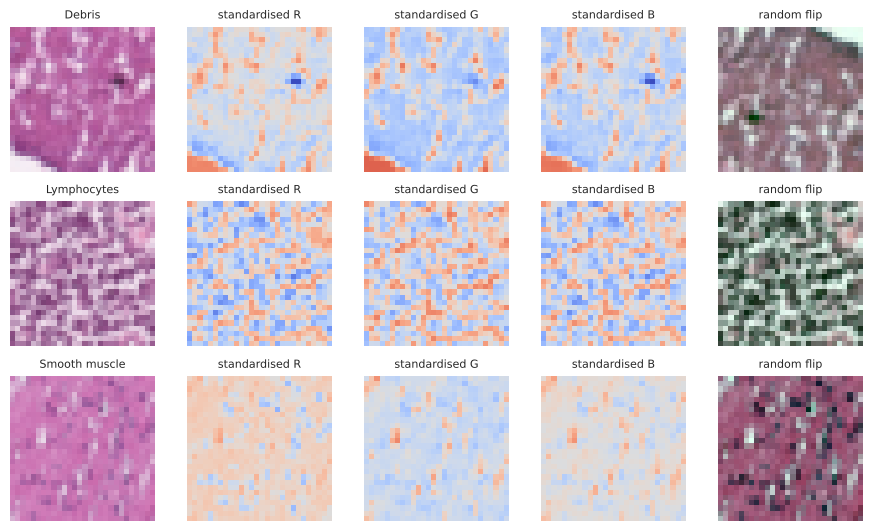

In [9]:
print("Random Forest input:", X_tr_flat.shape, f"values between {X_tr_flat.min():.2f} and {X_tr_flat.max():.2f}")
print("First 9 values of the first image (RGB of the first 3 pixels):", X_tr_flat[0, :9].round(3))
print()
print("Neural network input:", X_tr_nn.shape, X_tr_nn.dtype)
# float64 is used for the check because summing millions of float32 values loses precision
print("mean per channel after standardising (train):", X_tr_nn.reshape(-1, 3).astype(np.float64).mean(axis=0).round(3))
print("std per channel after standardising (train): ", X_tr_nn.reshape(-1, 3).astype(np.float64).std(axis=0).round(3))
print("mean per channel after standardising (test): ", X_test_nn.reshape(-1, 3).astype(np.float64).mean(axis=0).round(3))

# Show a few images: original, the three standardised channels, and a randomly flipped version
flip_layer = keras.layers.RandomFlip("horizontal_and_vertical", seed=SEED)

def to_display_range(img):
    """Min-max rescale an image to [0, 1] so that imshow can show it."""
    return (img - img.min()) / (img.max() - img.min())

fig, axes = plt.subplots(3, 5, figsize=(9, 5.4))
for row in range(3):
    axes[row, 0].imshow(X_tr[row])
    axes[row, 0].set_title(class_names[y_tr[row]], fontsize=8)
    for k, channel in enumerate("RGB"):
        axes[row, k + 1].imshow(X_tr_nn[row, :, :, k], cmap="coolwarm", vmin=-3, vmax=3)
        axes[row, k + 1].set_title(f"standardised {channel}", fontsize=8)
    flipped = flip_layer(X_tr_nn[row][None], training=True)[0].numpy()
    axes[row, 4].imshow(to_display_range(flipped))
    axes[row, 4].set_title("random flip", fontsize=8)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Algorithm design and setup

### Algorithm of choice from first six weeks of course

We use a **Random Forest** (week 5). Each tree is trained on a bootstrap sample and only looks at a random subset of the features at each split, and the forest predicts by majority vote. We chose it because it copes with 2352 raw features without any scaling, can model non-linear interactions between pixel colours, is fairly robust to overfitting, trains in parallel on a CPU, and gives feature importances that we can look at. kNN would be slow to predict with 32,000 stored images and suffers from the high dimension, an RBF SVM becomes expensive with this many training examples, and a single decision tree has high variance.

In [10]:
def make_random_forest(n_estimators=100, max_features="sqrt", max_depth=None, min_samples_leaf=1):
    """Return a Random Forest with the given hyperparameters (all CPU cores are used)."""
    return RandomForestClassifier(n_estimators=n_estimators,
                                  max_features=max_features,
                                  max_depth=max_depth,
                                  min_samples_leaf=min_samples_leaf,
                                  n_jobs=-1,
                                  random_state=SEED)

# Instance with the default settings (before tuning)
rf_untuned = make_random_forest()
print(rf_untuned)

RandomForestClassifier(n_jobs=-1, random_state=42)


### Fully connected neural network

The MLP flattens the image and passes it through `n_hidden_layers` dense layers with ReLU activations, each followed by dropout, and ends with a 9-unit softmax layer. All hidden layers have the same number of units so that depth and width can be tuned separately. It is trained with Adam on the sparse categorical cross-entropy loss with a batch size of 128, and early stopping on the validation loss.

In [11]:
input_shape = X_tr_nn.shape[1:]   # (28, 28, 3)

def build_mlp(n_hidden_layers=2, units=256, dropout=0.2, learning_rate=1e-3):
    """Build and compile a fully connected network."""
    model = keras.models.Sequential()
    model.add(keras.layers.Input(shape=input_shape))
    model.add(keras.layers.Flatten())
    for i in range(n_hidden_layers):
        model.add(keras.layers.Dense(units, activation="relu"))
        if dropout > 0:
            model.add(keras.layers.Dropout(dropout))
    model.add(keras.layers.Dense(n_classes, activation="softmax"))

    model.compile(loss="sparse_categorical_crossentropy",
                  optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  metrics=["accuracy"])
    return model

mlp_untuned = build_mlp()
mlp_untuned.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 2352)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       602,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 9)              │         2,313 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 670,473 (2.56 MB)

 Trainable params: 670,473 (2.56 MB)

 Non-trainable params: 0 (0.00 B)

### Convolutional neural network